## Lab 3: Convolutional Neural Networks: Application to Pneumonia Detection in Chest X-Rays

Àlex Font Bartumeus, 266147

Iris Azlor Solé, 266871

ATENTION! The plots on this jupyter notebook do not coincide with the ones from the report. Those plots were obtained through a GoogleColab run and the notebook was later downloaded and run locally to check it worked correctly before handing it in.

### Data Analysis

In this first step, we have to load the dataset, which is an npz file. This type of file is characterized by having a compressed binary NumPy format and is designed to store images and labels in data arrays saved in a single file using keys.

In [1]:
# We import the necessary libraries
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader

import numpy as np
import matplotlib.pyplot as plt

from torchvision import transforms
from PIL import Image

from sklearn.metrics import classification_report, ConfusionMatrixDisplay, RocCurveDisplay

In [2]:
# Fixed hyper-parameters for the model training (as defined in class)
IMG_HEIGHT, IMG_WIDTH = 28, 28
BATCH_SIZE = 16
NUM_EPOCHS = 15
LR = 0.001
random_seed = 17

# We fix one seed (random_seed = 17) so the randomness is always the same and good results are reproducible
torch.manual_seed(random_seed)
np.random.seed(random_seed)

# As we saw in class, we look if the computer has a gpu or not, if there is none, we will use the cpu
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device: ', device)

# 1. We load the dataset (.npz)
base_path = 'data/pneumonia_MNIST/pneumoniamnist.npz'
data = np.load(base_path)

# npz files store matrices with keys. Therefore, we print the list of keys:
print("Keys:", list(data.keys()))

Device:  cpu
Keys: ['train_images', 'val_images', 'test_images', 'train_labels', 'val_labels', 'test_labels']


Our keys are:
['train_images', 'val_images', 'test_images', 'train_labels', 'val_labels', 'test_labels']. 

As we already have the dataset split, we can load them.

In [3]:
X_train = data["train_images"]
y_train = data["train_labels"].squeeze() # Remove extra dimension of size 1 from labels

X_val = data["val_images"]
y_val = data["val_labels"].squeeze()

X_test = data["test_images"]
y_test = data["test_labels"].squeeze()

print("Train:", X_train.shape, y_train.shape)
print("Val:  ", X_val.shape, y_val.shape)
print("Test: ", X_test.shape, y_test.shape)

# We have obtained that our images have a size of 28x28, not the 128x128 we expected to have

Train: (4708, 28, 28) (4708,)
Val:   (524, 28, 28) (524,)
Test:  (624, 28, 28) (624,)


We see that inside the file npz we have the dataset already divided into training (4708 images), validation (524 images) and testing (624 images). This gives us a total of 5856 images and its labels inside the dataset.

In [4]:
# 2 Data Analysis
def class_distribution(y):
    # Check if the dataset is balanced or not
    unique, counts = np.unique(y, return_counts=True)
    return dict(zip(unique.tolist(), counts.tolist()))

print("Class dist train:", class_distribution(y_train))
print("Class dist val:  ", class_distribution(y_val))
print("Class dist test: ", class_distribution(y_test))

# 0: normal, 1: pneumonia

# Range of pixel intensities
print("Pixel range train:", X_train.min(), X_train.max())

Class dist train: {0: 1214, 1: 3494}
Class dist val:   {0: 135, 1: 389}
Class dist test:  {0: 234, 1: 390}
Pixel range train: 0 255


We have performed this analysis to obtain what is the distribution of each class. We know that class 0 corresponds to normal and class 1 to pneumonia.
In this case, we have that for training 1214 images correspond to normal and 3494 to pneumonia. We see that in each case (training, validation, testing) we have more images with class 1 than class 0.

In [5]:
'''
For the blood dataset we used ImageFolder because we had the images in different folders.
However, in this case, our dataset is made of an npz file and therefore we have to use transforms
because images are stored in matrices.
'''

# define a Dataset class to load the data from the npz file and apply the necessary transformations to convert the matrices into images that can be fed into our model
class NPZDataset(Dataset):
    def __init__(self, images, labels, transform=None):
        self.images = images
        self.labels = labels.astype(np.int64)
        self.transform = transform

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):
        img = self.images[idx]  # our size is 28x28
        label = self.labels[idx] # labels are 0 or 1

        # From numbers in the npz file to images
        img = Image.fromarray(img.astype(np.uint8), mode="L")

        if self.transform is not None: 
            img = self.transform(img)

        return img, torch.tensor(label, dtype=torch.long)


transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5], std=[0.5])
])

# Datasets
train_dataset = NPZDataset(X_train, y_train, transform=transform)
val_dataset   = NPZDataset(X_val,   y_val,   transform=transform)
test_dataset  = NPZDataset(X_test,  y_test,  transform=transform)

# DataLoaders
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True,
                          generator=torch.Generator().manual_seed(random_seed))
val_loader   = DataLoader(val_dataset,   batch_size=BATCH_SIZE, shuffle=False)
test_loader  = DataLoader(test_dataset,  batch_size=BATCH_SIZE, shuffle=False)

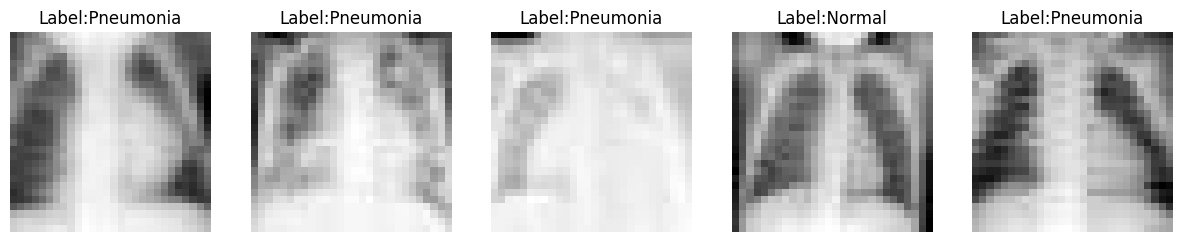

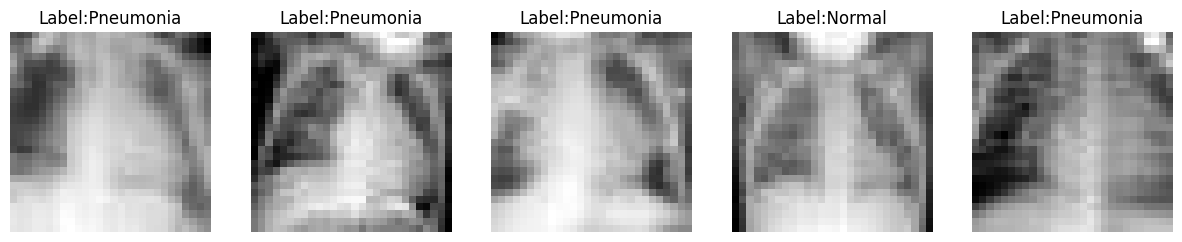

In [6]:
# 3 Visualize the images of this dataset as done for the blood dataset

def visualize_images(data_loader):
    images, labels = next(iter(data_loader))
    images, labels = images[:5], labels[:5]
    images = images.numpy().transpose((0, 2, 3, 1))

    label_map = {0:'Normal', 1:'Pneumonia'}
    fig, axes = plt.subplots(1, len(images), figsize=(15, 5))

    for i in range(len(images)):
        img = (images[i] * 0.5) + 0.5
        img = img.squeeze()  # Images are grayscale

        axes[i].imshow(img, cmap="gray", interpolation="nearest")
        axes[i].set_title(f'Label:{label_map[labels[i].item()]}')
        axes[i].axis('off')

    plt.show()

visualize_images(train_loader)
visualize_images(val_loader)

When we visualize the images we can see that they appear to have lots of pixels. This is due to the fact that our images have size 28x28 and when whe try to visualize them we are enlarging them which makes them blurry.

In [7]:
# UTILS functions for training, evaluation and visualization of results
def train_model(model, train_loader, val_loader, criterion, optimizer, num_epochs, device):
    train_losses, val_losses = [], []
    train_accs, val_accs = [], []

    for epoch in range(num_epochs):

        # TRAIN
        model.train()
        running_loss, correct, total = 0.0, 0, 0

        for images, labels in train_loader:
            images, labels = images.to(device), labels.to(device)

            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            running_loss += loss.item() * images.size(0)
            preds = outputs.argmax(dim=1)
            correct += (preds == labels).sum().item()
            total += labels.size(0)

        train_losses.append(running_loss / total)
        train_accs.append(correct / total)

        # VALIDATION
        model.eval()
        running_loss, correct, total = 0.0, 0, 0

        with torch.no_grad():
            for images, labels in val_loader:
                images, labels = images.to(device), labels.to(device)

                outputs = model(images)
                loss = criterion(outputs, labels)

                running_loss += loss.item() * images.size(0)
                preds = outputs.argmax(dim=1)
                correct += (preds == labels).sum().item()
                total += labels.size(0)

        val_losses.append(running_loss / total)
        val_accs.append(correct / total)

        print(f"Epoch {epoch+1}/{num_epochs} | "
              f"Train loss {train_losses[-1]:.4f} acc {train_accs[-1]:.4f} | "
              f"Val loss {val_losses[-1]:.4f} acc {val_accs[-1]:.4f}")

    return train_losses, val_losses, train_accs, val_accs


def evaluate_model(model, data_loader, device):
    model.eval()
    all_labels, all_preds, all_probs = [], [], []
    softmax = nn.Softmax(dim=1)

    with torch.no_grad():
        for images, labels in data_loader:
            images = images.to(device)
            outputs = model(images)

            probs = softmax(outputs).cpu().numpy()
            preds = outputs.argmax(dim=1).cpu().numpy()

            all_probs.append(probs)
            all_preds.append(preds)
            all_labels.append(labels.numpy())

    all_labels = np.concatenate(all_labels)
    all_preds  = np.concatenate(all_preds)
    all_probs  = np.concatenate(all_probs)

    return all_labels, all_preds, all_probs


def plot_curves(train_losses, val_losses, train_accs, val_accs):
    plt.figure()
    plt.plot(train_losses, label="Train Loss")
    plt.plot(val_losses, label="Val Loss")
    plt.xlabel("Epoch")
    plt.legend()
    plt.title("Training and Validation Loss")
    plt.show()

    plt.figure()
    plt.plot(train_accs, label="Train Accuracy")
    plt.plot(val_accs, label="Val Accuracy")
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.legend()
    plt.title("Training and Validation Accuracy")
    plt.show()


def visualize_results(all_labels, all_preds, all_probs, title=""):
    target_names = ["Normal", "Pneumonia"]

    print(title)
    print(classification_report(all_labels, all_preds, target_names=target_names))

    ConfusionMatrixDisplay.from_predictions(
        all_labels, all_preds,
        display_labels=target_names,
        cmap="Blues"
    )
    plt.title(f"{title} - Confusion Matrix")
    plt.show()

    RocCurveDisplay.from_predictions(
        all_labels,
        all_probs[:, 1],
        pos_label=1,
        name=title
    )
    plt.title(f"{title} - ROC")
    plt.show()

### Baseline model

In [8]:
# Same baseline model as in class but adapted for a different image size
# A simple CNN with 2 convolutional layers and 2 fully connected layers. 
# Input size is adapted to our images (28x28) and the output layer has 2 neurons for the two classes (normal and pneumonia).
class PneumoniaCNN(nn.Module):
    def __init__(self):
        super(PneumoniaCNN, self).__init__()

        self.features = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, padding=1),  # (1,28,28)->(32,28,28)
            nn.ReLU(),
            nn.MaxPool2d(2)                              # -> (32,14,14)
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(32 * 14 * 14, 2)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x

baseline_model = PneumoniaCNN().to(device)
print(baseline_model)

PneumoniaCNN(
  (features): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=6272, out_features=2, bias=True)
  )
)


Epoch 1/15 | Train loss 0.1791 acc 0.9303 | Val loss 0.1651 acc 0.9351
Epoch 2/15 | Train loss 0.1233 acc 0.9539 | Val loss 0.1062 acc 0.9580
Epoch 3/15 | Train loss 0.1078 acc 0.9605 | Val loss 0.0976 acc 0.9561
Epoch 4/15 | Train loss 0.0898 acc 0.9677 | Val loss 0.1071 acc 0.9618
Epoch 5/15 | Train loss 0.0868 acc 0.9701 | Val loss 0.0925 acc 0.9618
Epoch 6/15 | Train loss 0.0846 acc 0.9703 | Val loss 0.0959 acc 0.9637
Epoch 7/15 | Train loss 0.0707 acc 0.9754 | Val loss 0.0948 acc 0.9656
Epoch 8/15 | Train loss 0.0700 acc 0.9739 | Val loss 0.0911 acc 0.9656
Epoch 9/15 | Train loss 0.0680 acc 0.9766 | Val loss 0.0866 acc 0.9676
Epoch 10/15 | Train loss 0.0578 acc 0.9794 | Val loss 0.0891 acc 0.9676
Epoch 11/15 | Train loss 0.0608 acc 0.9783 | Val loss 0.0855 acc 0.9676
Epoch 12/15 | Train loss 0.0550 acc 0.9794 | Val loss 0.0883 acc 0.9656
Epoch 13/15 | Train loss 0.0525 acc 0.9800 | Val loss 0.0916 acc 0.9618
Epoch 14/15 | Train loss 0.0637 acc 0.9734 | Val loss 0.0850 acc 0.9637
E

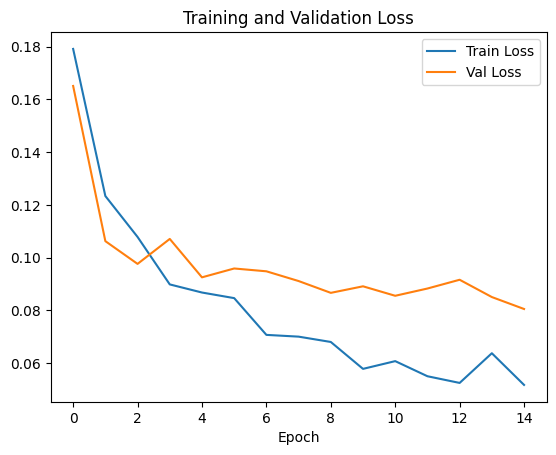

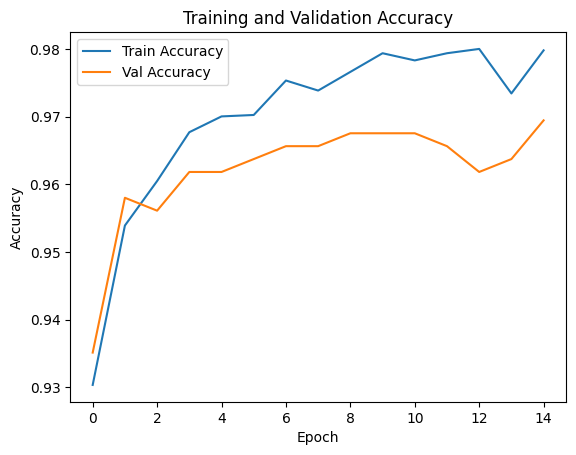

In [9]:
torch.manual_seed(random_seed) # ensure reproducibility for training

criterion = nn.CrossEntropyLoss()   # define a loss function for multi-class classification
optimizer = optim.Adam(baseline_model.parameters(), lr=LR) # define an optimizer (Adam) to update the model parameters

train_losses, val_losses, train_accs, val_accs = train_model(
    baseline_model, train_loader, val_loader, criterion, optimizer, NUM_EPOCHS, device
)   # train the model and obtain the training and validation losses and accuracies for each epoch

plot_curves(train_losses, val_losses, train_accs, val_accs)

These results align with a baseline that converges well, the train and validation loss decrease and the accuracy grows. In the first epoch, the model is approximately 93% accurate in both training and validation. The model learns quickly and performs much better than guessing randomly. As the epochs progress, the train loss decreases and the accuracy increases, suggesting that the model learns the training examples better and better, eventually achieving 98% accuracy. Regarding accuracy, we see that it increases, but the loss exhibits a pattern of ups and downs. This suggests that the model also improves in validation, but reaches a point where it plateaus slightly and no longer improves.

In conclusion, we see that the baseline learns because the loss decreases and the accuracy increases. Furthermore, we have obtained approximately 97% validation accuracy with a simple CNN. However, it is also important to note a slight overfitting starting in epoch 5, where, although the training continues to improve, the validation no longer improves as significantly.

BASELINE (VAL)
              precision    recall  f1-score   support

      Normal       0.95      0.93      0.94       135
   Pneumonia       0.98      0.98      0.98       389

    accuracy                           0.97       524
   macro avg       0.96      0.96      0.96       524
weighted avg       0.97      0.97      0.97       524



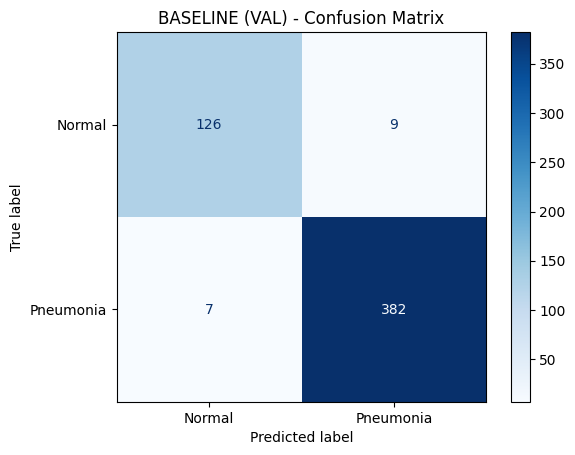

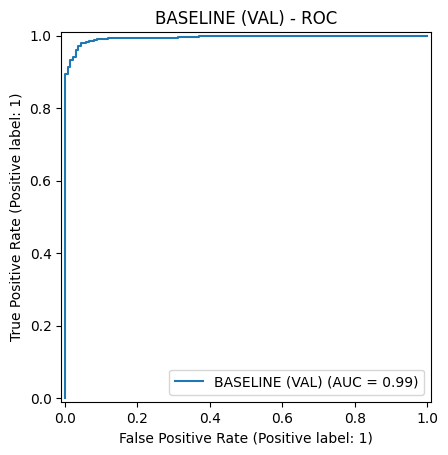

In [10]:
# Evaluate the model on the validation set and visualize the results
all_labels, all_preds, all_probs = evaluate_model(baseline_model, val_loader, device)
visualize_results(all_labels, all_preds, all_probs, title="BASELINE (VAL)")

If we plot the confusion matrix of our baseline, we see that the model makes few errors:

    - False positives: 7

    - False negatives: 9

    - Total errors: 16

In total, 508 out of 524 cases are correctly identified, giving us an accuracy of approximately 97%, as we saw earlier.

From a clinical perspective, the most serious errors are those related to false negatives, since in this case we are missing cases of pneumonia. However, despite these errors, the model performs very well in these categories, as the AUC is 0.99.

If we look at the results of evaluating the precision/recall/f1-score models, we see that we have greater accuracy regarding pneumonia cases in all metrics. However, when we look at the support variable (how many examples there are of each class), we see a clear imbalance:

    - Normal: 135

    - Pneumonia: 389
    
This imbalance can inflate the accuracy values, as the model may obtain high values ​​by accurately predicting the majority class.

### Improvements

#### First improvement: Data augmentation

In [11]:
# In this part only the train set is augmented, we keep the val and test clean

# Apply flipping, rotation, affine to the train set
train_transform = transforms.Compose([
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=5),
    transforms.RandomAffine(degrees=0, translate=(0.02, 0.02), scale=(0.98, 1.02)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5], std=[0.5])
])

# No changes applied to evaluation transform
eval_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5], std=[0.5])
])

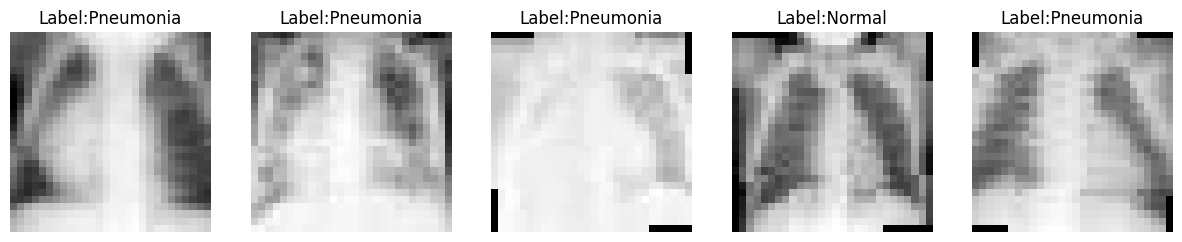

In [12]:
# Remake the datasets
train_dataset_aug = NPZDataset(X_train, y_train, transform=train_transform)
val_dataset_aug   = NPZDataset(X_val,   y_val,   transform=eval_transform)
test_dataset_aug  = NPZDataset(X_test,  y_test,  transform=eval_transform)

train_loader_aug = DataLoader(train_dataset_aug, batch_size=BATCH_SIZE, shuffle=True,
                              generator=torch.Generator().manual_seed(random_seed))
val_loader_aug   = DataLoader(val_dataset_aug, batch_size=BATCH_SIZE, shuffle=False)
test_loader_aug  = DataLoader(test_dataset_aug, batch_size=BATCH_SIZE, shuffle=False)

visualize_images(train_loader_aug)

Epoch 1/15 | Train loss 0.2172 acc 0.9114 | Val loss 0.1592 acc 0.9466
Epoch 2/15 | Train loss 0.1606 acc 0.9386 | Val loss 0.1293 acc 0.9523
Epoch 3/15 | Train loss 0.1396 acc 0.9486 | Val loss 0.1276 acc 0.9523
Epoch 4/15 | Train loss 0.1237 acc 0.9535 | Val loss 0.1373 acc 0.9523
Epoch 5/15 | Train loss 0.1261 acc 0.9539 | Val loss 0.1229 acc 0.9542
Epoch 6/15 | Train loss 0.1199 acc 0.9539 | Val loss 0.1022 acc 0.9580
Epoch 7/15 | Train loss 0.1125 acc 0.9586 | Val loss 0.1187 acc 0.9542
Epoch 8/15 | Train loss 0.1113 acc 0.9599 | Val loss 0.0976 acc 0.9618
Epoch 9/15 | Train loss 0.1060 acc 0.9601 | Val loss 0.1284 acc 0.9523
Epoch 10/15 | Train loss 0.0954 acc 0.9643 | Val loss 0.0984 acc 0.9599
Epoch 11/15 | Train loss 0.1061 acc 0.9613 | Val loss 0.0950 acc 0.9599
Epoch 12/15 | Train loss 0.0995 acc 0.9620 | Val loss 0.1001 acc 0.9656
Epoch 13/15 | Train loss 0.0915 acc 0.9677 | Val loss 0.0875 acc 0.9656
Epoch 14/15 | Train loss 0.1058 acc 0.9599 | Val loss 0.0888 acc 0.9618
E

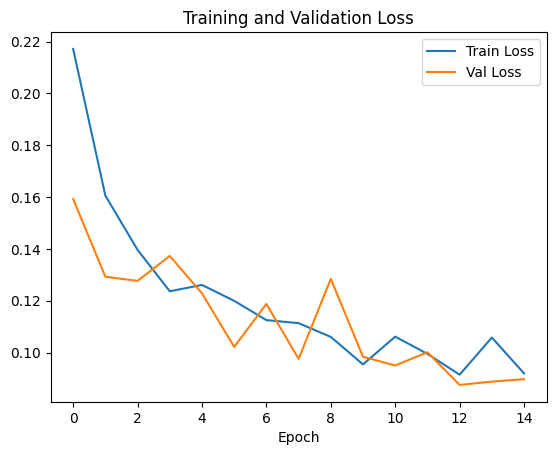

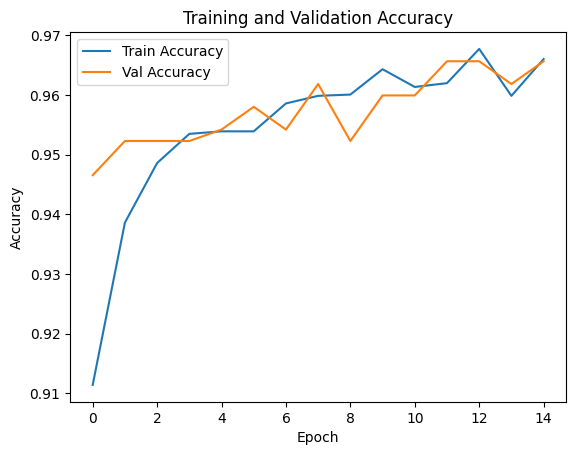

In [13]:
# Train the same baseline but with the "new" augmented dataset
torch.manual_seed(random_seed) # ensure reproducibility for training with the augmented dataset

baseline_aug = PneumoniaCNN().to(device)

criterion = nn.CrossEntropyLoss() # define a loss function for multi-class classification
optimizer = optim.Adam(baseline_aug.parameters(), lr=LR) # define an optimizer (Adam) to update the model parameters

train_losses, val_losses, train_accs, val_accs = train_model(
    baseline_aug, train_loader_aug, val_loader_aug, criterion, optimizer, NUM_EPOCHS, device
) # train the model and obtain the training and validation losses and accuracies for each epoch

plot_curves(train_losses, val_losses, train_accs, val_accs)

BASELINE + AUGMENTATIONS (VAL)
              precision    recall  f1-score   support

      Normal       0.95      0.91      0.93       135
   Pneumonia       0.97      0.98      0.98       389

    accuracy                           0.97       524
   macro avg       0.96      0.95      0.95       524
weighted avg       0.97      0.97      0.97       524



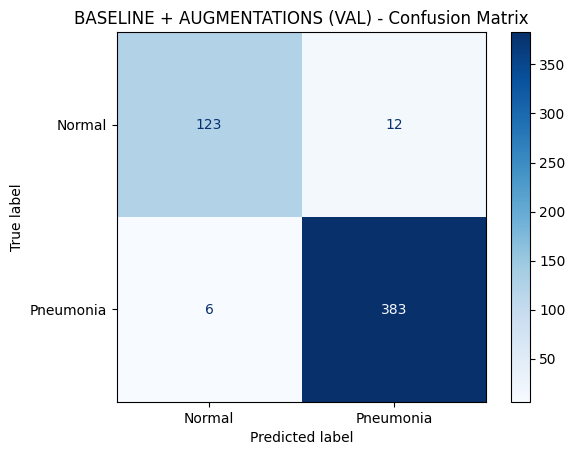

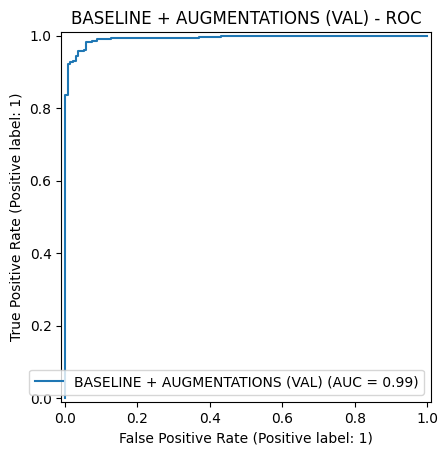

In [14]:
# Evaluate the model on the validation set and visualize the results
all_labels, all_preds, all_probs = evaluate_model(baseline_aug, val_loader_aug, device)
visualize_results(all_labels, all_preds, all_probs, title="BASELINE + AUGMENTATIONS (VAL)")

#### Second improvement: Deep CNN architecture

In [15]:
# In this part, the model is improved to Deep CNN architecture and it is trained with the previous augmentation
class PneumoniaCNN_Improved(nn.Module):
    def __init__(self):
        super(PneumoniaCNN_Improved, self).__init__()

        self.features = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 7 * 7, 2)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x

Epoch 1/15 | Train loss 0.2261 acc 0.9091 | Val loss 0.2391 acc 0.9008
Epoch 2/15 | Train loss 0.1490 acc 0.9403 | Val loss 0.1280 acc 0.9504
Epoch 3/15 | Train loss 0.1357 acc 0.9480 | Val loss 0.1438 acc 0.9542
Epoch 4/15 | Train loss 0.1189 acc 0.9558 | Val loss 0.1193 acc 0.9580
Epoch 5/15 | Train loss 0.1149 acc 0.9558 | Val loss 0.1554 acc 0.9389
Epoch 6/15 | Train loss 0.1060 acc 0.9613 | Val loss 0.1641 acc 0.9485
Epoch 7/15 | Train loss 0.1019 acc 0.9626 | Val loss 0.0876 acc 0.9695
Epoch 8/15 | Train loss 0.0908 acc 0.9635 | Val loss 0.1055 acc 0.9637
Epoch 9/15 | Train loss 0.0925 acc 0.9652 | Val loss 0.0807 acc 0.9695
Epoch 10/15 | Train loss 0.0860 acc 0.9675 | Val loss 0.0849 acc 0.9676
Epoch 11/15 | Train loss 0.0840 acc 0.9690 | Val loss 0.0867 acc 0.9676
Epoch 12/15 | Train loss 0.0747 acc 0.9724 | Val loss 0.0837 acc 0.9637
Epoch 13/15 | Train loss 0.0844 acc 0.9669 | Val loss 0.0798 acc 0.9733
Epoch 14/15 | Train loss 0.0774 acc 0.9690 | Val loss 0.0732 acc 0.9733
E

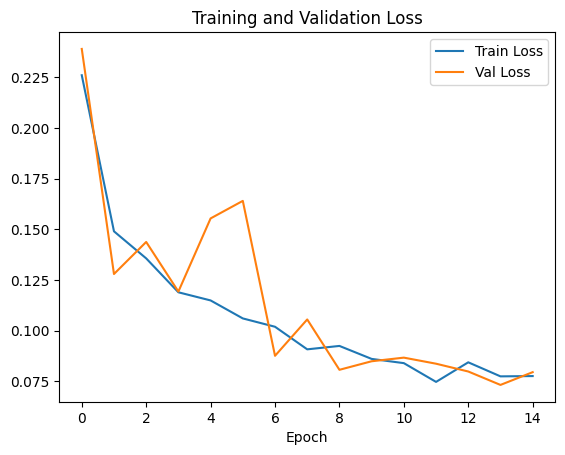

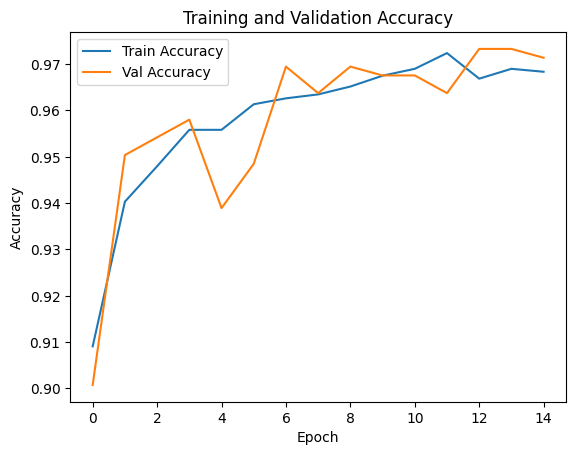

In [16]:
# Two-way improved model with the augmentation and the improved architecture
torch.manual_seed(random_seed) # ensure reproducibility for training

two_way_model = PneumoniaCNN_Improved().to(device)

criterion = nn.CrossEntropyLoss() # define a loss function for multi-class classification
optimizer = optim.Adam(two_way_model.parameters(), lr=LR) # define an optimizer (Adam) to update the model parameters

train_losses, val_losses, train_accs, val_accs = train_model(
    two_way_model, train_loader_aug, val_loader_aug, criterion, optimizer, NUM_EPOCHS, device
) # train the model and obtain the training and validation losses and accuracies for each epoch

plot_curves(train_losses, val_losses, train_accs, val_accs)

TWO-WAY IMPROVED (VAL)
              precision    recall  f1-score   support

      Normal       0.93      0.96      0.95       135
   Pneumonia       0.98      0.98      0.98       389

    accuracy                           0.97       524
   macro avg       0.96      0.97      0.96       524
weighted avg       0.97      0.97      0.97       524



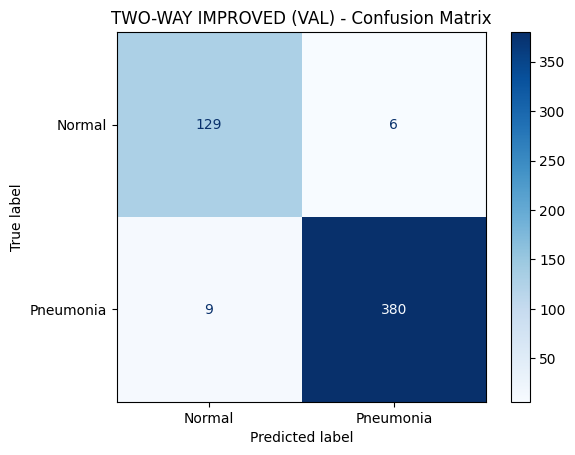

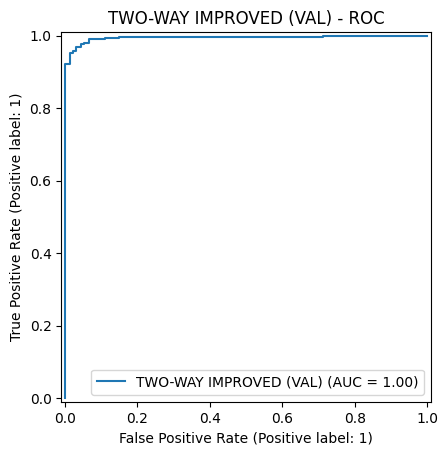

In [17]:
# Evaluate the model on the validation set and visualize the results
all_labels, all_preds, all_probs = evaluate_model(two_way_model, val_loader_aug, device)
visualize_results(all_labels, all_preds, all_probs, title="TWO-WAY IMPROVED (VAL)")

#### Fine-tune a pre-trained model

In [18]:
# As propossed in the lab instruction, use ResNet-50 model (pretrained on ImageNet)
# Use pretrained weights and adapt the input and output layers to our problem.
from torchvision.transforms import InterpolationMode
from torchvision import models

# 3 channels are expected for ResNet-50 
resnet_train_transform = transforms.Compose([
    transforms.Resize((224, 224), interpolation=InterpolationMode.BILINEAR),
    transforms.Grayscale(num_output_channels=3),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=5),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5,0.5,0.5], std=[0.5,0.5,0.5])
])

resnet_eval_transform = transforms.Compose([
    transforms.Resize((224, 224), interpolation=InterpolationMode.BILINEAR),
    transforms.Grayscale(num_output_channels=3),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5,0.5,0.5], std=[0.5,0.5,0.5])
])

train_dataset_resnet = NPZDataset(X_train, y_train, transform=resnet_train_transform)
val_dataset_resnet   = NPZDataset(X_val,   y_val,   transform=resnet_eval_transform)
test_dataset_resnet  = NPZDataset(X_test,  y_test,  transform=resnet_eval_transform)

train_loader_resnet = DataLoader(train_dataset_resnet, batch_size=BATCH_SIZE, shuffle=True,
                                 generator=torch.Generator().manual_seed(random_seed))
val_loader_resnet   = DataLoader(val_dataset_resnet, batch_size=BATCH_SIZE, shuffle=False)
test_loader_resnet  = DataLoader(test_dataset_resnet, batch_size=BATCH_SIZE, shuffle=False)

Epoch 1/15 | Train loss 0.2292 acc 0.9070 | Val loss 0.1743 acc 0.9427
Epoch 2/15 | Train loss 0.1830 acc 0.9301 | Val loss 0.2421 acc 0.8989
Epoch 3/15 | Train loss 0.1685 acc 0.9346 | Val loss 0.1319 acc 0.9504
Epoch 4/15 | Train loss 0.1356 acc 0.9475 | Val loss 0.1239 acc 0.9542
Epoch 5/15 | Train loss 0.1238 acc 0.9545 | Val loss 0.1500 acc 0.9332
Epoch 6/15 | Train loss 0.1233 acc 0.9526 | Val loss 0.1013 acc 0.9637
Epoch 7/15 | Train loss 0.1189 acc 0.9539 | Val loss 0.0939 acc 0.9618
Epoch 8/15 | Train loss 0.1166 acc 0.9569 | Val loss 0.0949 acc 0.9637
Epoch 9/15 | Train loss 0.1146 acc 0.9575 | Val loss 0.4666 acc 0.8321
Epoch 10/15 | Train loss 0.1089 acc 0.9592 | Val loss 0.0811 acc 0.9656
Epoch 11/15 | Train loss 0.1054 acc 0.9607 | Val loss 0.0982 acc 0.9637
Epoch 12/15 | Train loss 0.1001 acc 0.9609 | Val loss 0.0923 acc 0.9714
Epoch 13/15 | Train loss 0.0986 acc 0.9647 | Val loss 0.0889 acc 0.9637
Epoch 14/15 | Train loss 0.0943 acc 0.9622 | Val loss 0.0669 acc 0.9771
E

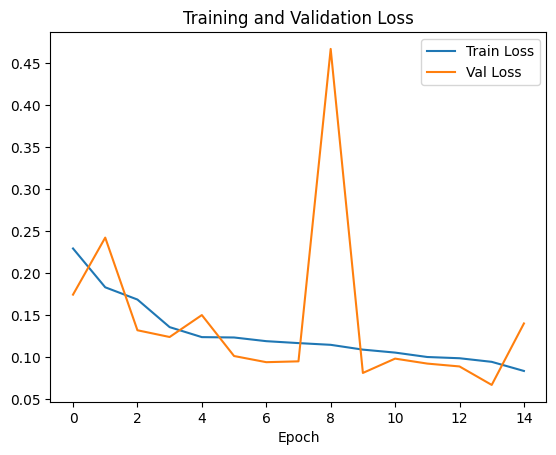

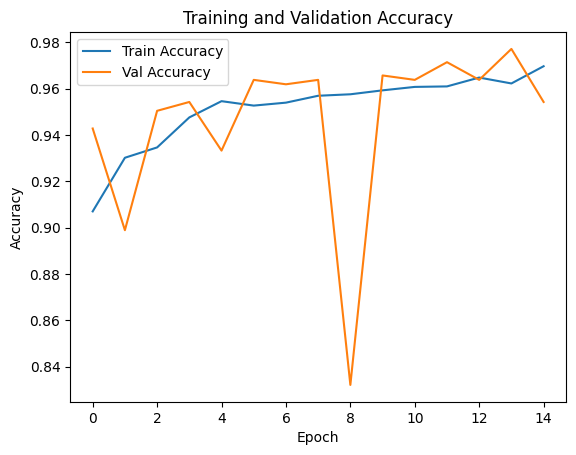

In [20]:
# pretrain the ResNet
resnet_model = models.resnet50(pretrained=True).to(device)

# Replace the last layer for a two-class classification
resnet_model.fc = nn.Linear(resnet_model.fc.in_features, 2).to(device)

torch.manual_seed(random_seed)

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(resnet_model.parameters(), lr=LR)

train_losses, val_losses, train_accs, val_accs = train_model(
    resnet_model, train_loader_resnet, val_loader_resnet, criterion, optimizer, NUM_EPOCHS, device
)

plot_curves(train_losses, val_losses, train_accs, val_accs)

RESNET-50 FT (VAL)
              precision    recall  f1-score   support

      Normal       0.85      0.99      0.92       135
   Pneumonia       1.00      0.94      0.97       389

    accuracy                           0.95       524
   macro avg       0.93      0.97      0.94       524
weighted avg       0.96      0.95      0.96       524



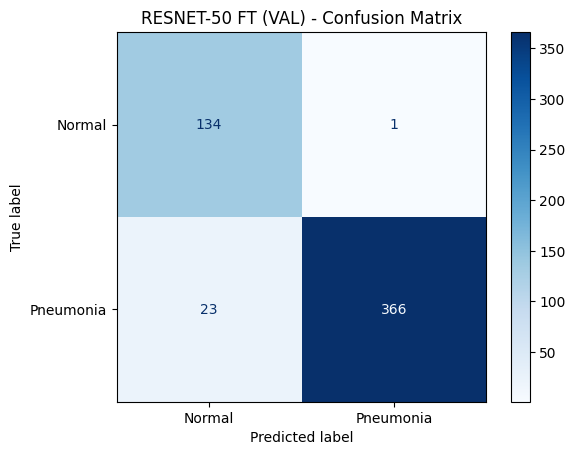

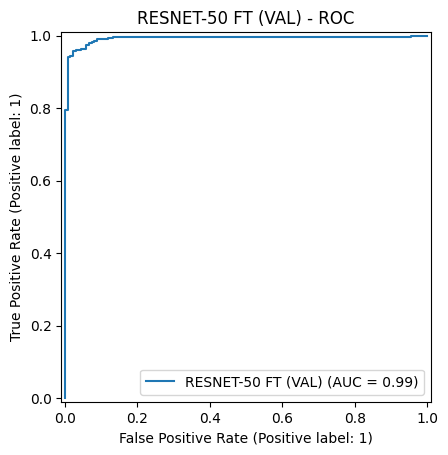

In [21]:
# Evaluate the model on the validation set and visualize the results
all_labels, all_preds, all_probs = evaluate_model(resnet_model, val_loader_resnet, device)
visualize_results(all_labels, all_preds, all_probs, title="RESNET-50 FT (VAL)")

#### Evaluation

Test metrics
Baseline:          AUC=0.9297 | F1=0.8846
Two-way improved:  AUC=0.9328 | F1=0.9002
ResNet-50 FT:      AUC=0.9667 | F1=0.9403
BASELINE (TEST)
              precision    recall  f1-score   support

      Normal       0.98      0.58      0.73       234
   Pneumonia       0.80      0.99      0.88       390

    accuracy                           0.84       624
   macro avg       0.89      0.79      0.81       624
weighted avg       0.87      0.84      0.83       624



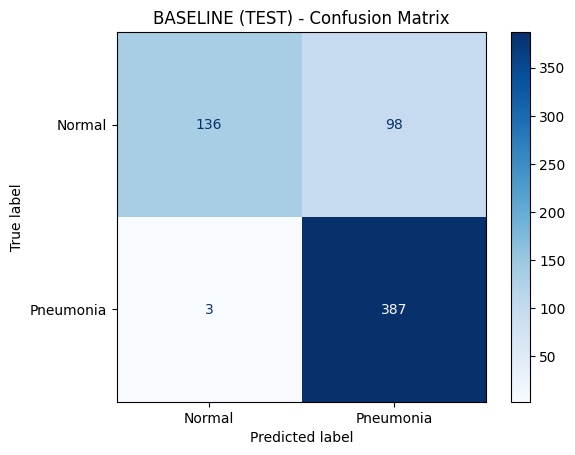

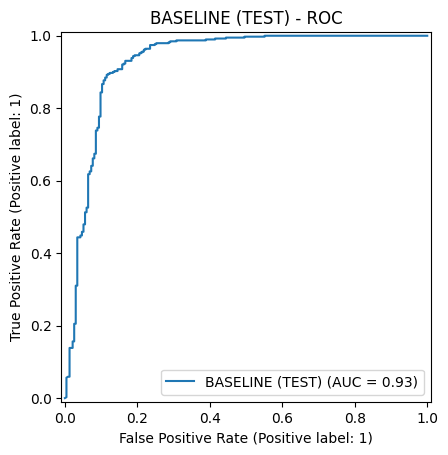

TWO-WAY IMPROVED (TEST)
              precision    recall  f1-score   support

      Normal       0.99      0.64      0.78       234
   Pneumonia       0.82      0.99      0.90       390

    accuracy                           0.86       624
   macro avg       0.90      0.82      0.84       624
weighted avg       0.88      0.86      0.85       624



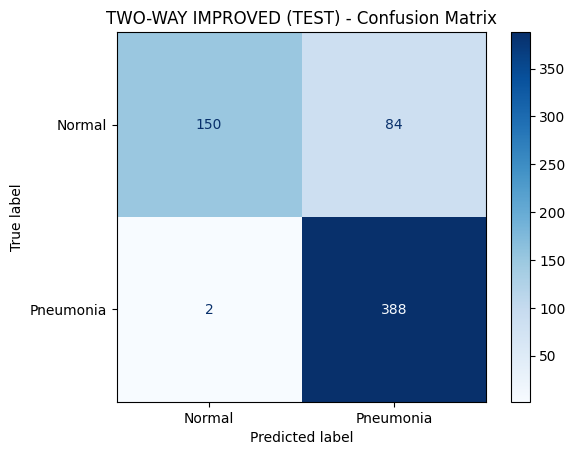

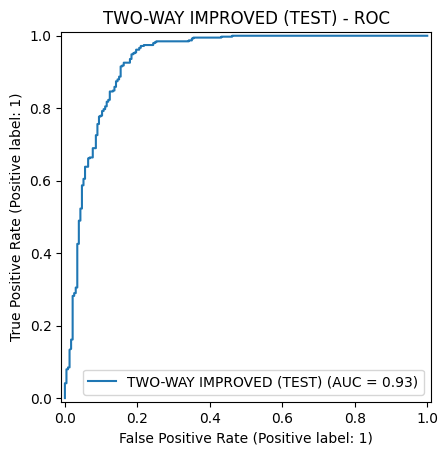

RESNET-50 FT (TEST)
              precision    recall  f1-score   support

      Normal       0.94      0.85      0.89       234
   Pneumonia       0.91      0.97      0.94       390

    accuracy                           0.92       624
   macro avg       0.93      0.91      0.92       624
weighted avg       0.92      0.92      0.92       624



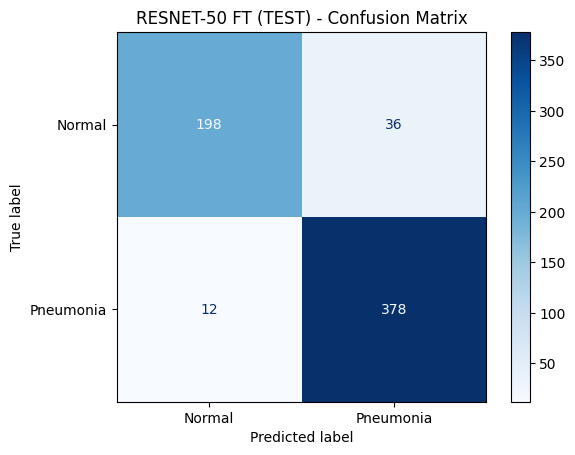

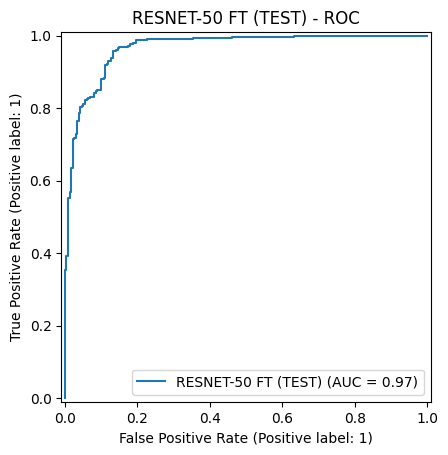

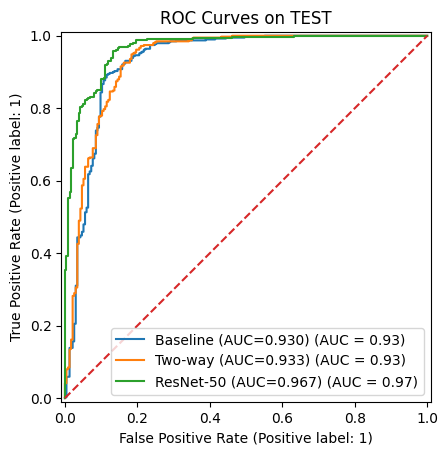

In [22]:
from sklearn.metrics import roc_auc_score, f1_score

# BASELINE
y_b, pred_b, prob_b = evaluate_model(baseline_model, test_loader, device)
auc_b = roc_auc_score(y_b, prob_b[:,1])
f1_b  = f1_score(y_b, pred_b)

# IMPROVED MODEL
y_t, pred_t, prob_t = evaluate_model(two_way_model, test_loader_aug, device)
auc_t = roc_auc_score(y_t, prob_t[:,1])
f1_t  = f1_score(y_t, pred_t)

# RESNET-50
y_r, pred_r, prob_r = evaluate_model(resnet_model, test_loader_resnet, device)
auc_r = roc_auc_score(y_r, prob_r[:,1])
f1_r  = f1_score(y_r, pred_r)

# Metrics
print("Test metrics")
print(f"Baseline:          AUC={auc_b:.4f} | F1={f1_b:.4f}")
print(f"Two-way improved:  AUC={auc_t:.4f} | F1={f1_t:.4f}")
print(f"ResNet-50 FT:      AUC={auc_r:.4f} | F1={f1_r:.4f}")

# Full reports
visualize_results(y_b, pred_b, prob_b, title="BASELINE (TEST)")
visualize_results(y_t, pred_t, prob_t, title="TWO-WAY IMPROVED (TEST)")
visualize_results(y_r, pred_r, prob_r, title="RESNET-50 FT (TEST)")

# One graph of ROC curves
fig, ax = plt.subplots()  # un solo axes

RocCurveDisplay.from_predictions(
    y_b, prob_b[:,1], pos_label=1,
    name=f"Baseline (AUC={auc_b:.3f})",
    ax=ax
)
RocCurveDisplay.from_predictions(
    y_t, prob_t[:,1], pos_label=1,
    name=f"Two-way (AUC={auc_t:.3f})",
    ax=ax
)
RocCurveDisplay.from_predictions(
    y_r, prob_r[:,1], pos_label=1,
    name=f"ResNet-50 (AUC={auc_r:.3f})",
    ax=ax
)

ax.plot([0,1], [0,1], "--")
ax.set_title("ROC Curves on TEST")
plt.show()

Values ​​to complete the report table:

In [23]:
def get_auc_f1(model, loader, device):
    y, pred, prob = evaluate_model(model, loader, device)
    auc = roc_auc_score(y, prob[:, 1])
    f1  = f1_score(y, pred)
    return auc, f1

def print_row(model_name, train_loader, val_loader, test_loader, model_obj):
    auc_tr, f1_tr = get_auc_f1(model_obj, train_loader, device)
    auc_va, f1_va = get_auc_f1(model_obj, val_loader, device)
    auc_te, f1_te = get_auc_f1(model_obj, test_loader, device)

    print(f"{model_name}")
    print(f"  Train: AUC/F1 = {auc_tr:.4f}/{f1_tr:.4f}")
    print(f"  Val:   AUC/F1 = {auc_va:.4f}/{f1_va:.4f}")
    print(f"  Test:  AUC/F1 = {auc_te:.4f}/{f1_te:.4f}")
    print("-"*40)

# Baseline
print_row("Baseline", train_loader, val_loader, test_loader, baseline_model)

# Improvements
print_row("Improved (two-way)", train_loader_aug, val_loader_aug, test_loader_aug, two_way_model)

# ResNet50
print_row("Fine-tuned (ResNet-50)", train_loader_resnet, val_loader_resnet, test_loader_resnet, resnet_model)

Baseline
  Train: AUC/F1 = 0.9990/0.9907
  Val:   AUC/F1 = 0.9950/0.9795
  Test:  AUC/F1 = 0.9297/0.8846
----------------------------------------
Improved (two-way)
  Train: AUC/F1 = 0.9973/0.9845
  Val:   AUC/F1 = 0.9953/0.9806
  Test:  AUC/F1 = 0.9328/0.9002
----------------------------------------
Fine-tuned (ResNet-50)
  Train: AUC/F1 = 0.9955/0.9671
  Val:   AUC/F1 = 0.9932/0.9683
  Test:  AUC/F1 = 0.9667/0.9403
----------------------------------------
